In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

In [2]:
X, y = make_moons(n_samples=300, noise=0.1, random_state=42)
print("Dataset shape:", X.shape)

Dataset shape: (300, 2)


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized dataset shape:", X_scaled.shape)

Standardized dataset shape: (300, 2)


In [4]:
eps_value = 0.3
min_samples_value = 5
print("Epsilon:", eps_value)
print("Minimum samples:", min_samples_value)

Epsilon: 0.3
Minimum samples: 5


In [5]:
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
labels = dbscan.fit_predict(X_scaled)
unique_labels = set(labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = list(labels).count(-1)

In [6]:
print("--- DBSCAN Clustering Results ---")
print("Estimated Number of Clusters:", n_clusters)
print("Identified Noise Points (-1):", n_noise, "out of", len(labels), "total points")

--- DBSCAN Clustering Results ---
Estimated Number of Clusters: 2
Identified Noise Points (-1): 2 out of 300 total points


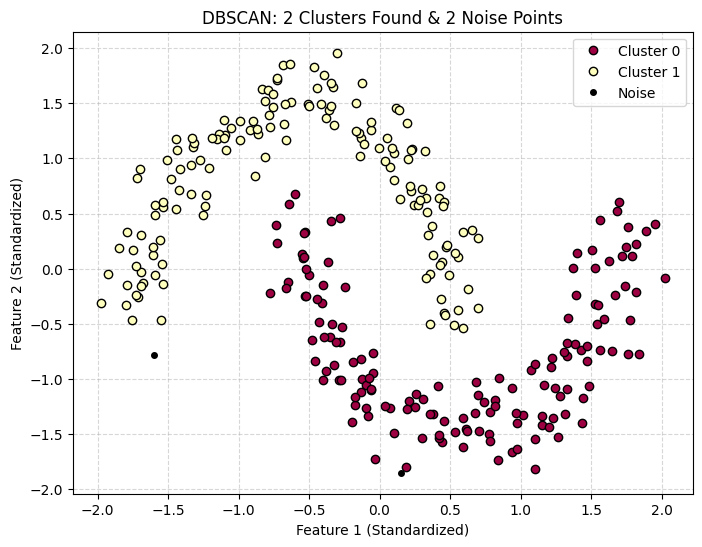

In [7]:
plt.figure(figsize=(8, 6))
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for label, color in zip(unique_labels, colors):
    if label == -1:
        color = [0, 0, 0, 1]
    class_member_mask = labels == label
    points = X_scaled[class_member_mask]
    plt.plot(
        points[:, 0], points[:, 1], "o",
        markerfacecolor=tuple(color), markeredgecolor="k",
        markersize=6 if label != -1 else 4,
        label=f"Cluster {label}" if label != -1 else "Noise"
    )
plt.title(f"DBSCAN: {n_clusters} Clusters Found & {n_noise} Noise Points")
plt.xlabel("Feature 1 (Standardized)")
plt.ylabel("Feature 2 (Standardized)")
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()